# 07. PyTorch İle Yapısal Model Eğitimi (nn.Linear Katmanı)

Bu notebook'ta manuel parametre tanımlamak (`weights`, `bias`) yerine PyTorch'un hazır katmanı olan `nn.Linear` kullanımını, tensör boyut ve tür zorunluluklarını (`float32` ve 2D `unsqueeze`), 5 adımlı eğitim döngüsünü ve eğitilmiş modelin değerlendirilmesini öğreniyoruz.

---
### 📌 İçindekiler
1. [Ortam Kurulumu ve Veri Yükleme](#1-ortam-kurulumu-ve-veri-yükleme)
2. [Veri Tipi (dtype) ve Boyut Dönüşümü (unsqueeze & float32)](#2-veri-tipi-dtype-ve-boyut-dönüşümü-unsqueeze--float32)
3. [PyTorch Yapısal Model Mimarisi (nn.Linear)](#3-pytorch-yapısal-model-mimarisi-nnlinear)
4. [Kayıp Fonksiyonu (Loss) ve İyileştirici (Optimizer)](#4-kayıp-fonksiyonu-loss-ve-İyileştirici-optimizer)
5. [Modelin Eğitilmesi (Training Loop - 5 Altın Adım)](#5-modelin-eğitilmesi-training-loop---5-altın-adım)
6. [Eğitilmiş Model İle Nihai Tahminler (Evaluation)](#6-eğitilmiş-model-İle-nihai-tahminler-evaluation)
7. [Modeli İyileştirme & Kapasite Artırma (Underfitting)](#7-modeli-İyileştirme--kapasite-artırma-underfitting)


## 1. Ortam Kurulumu ve Veri Yükleme


In [1]:
import pandas as pd
import torch
import matplotlib.pyplot as plt

In [2]:
# get data ready
df = pd.read_csv("06-study_hours_grades.csv")

In [3]:
df.head()

,study_hours,grade
0,3.745401,30.203939
1,9.507143,57.878452
2,7.319939,46.368401
3,5.986585,39.330717
4,1.560186,14.843888


In [4]:
df.head()

,study_hours,grade
0,3.745401,30.203939
1,9.507143,57.878452
2,7.319939,46.368401
3,5.986585,39.330717
4,1.560186,14.843888


## 2. Veri Tipi (dtype) ve Boyut Dönüşümü (unsqueeze & float32)

> ⚠️ **`nn.Linear` İçin İki Kritik Kural:**
1. **Veri Tipi (`float32`):** `nn.Linear` varsayılan olarak `float32` ağırlıklar kullanır. Pandas dizileri varsayılan `float64` (double) geldiği için `dtype=torch.float32` belirtmeliyiz, aksi takdirde `RuntimeError: mat1 and mat2 must have the same dtype` hatası alınır.
2. **Boyut Eksen Sayısı (2D Tensor):** `nn.Linear` katmanı girdinin `(batch_size, in_features)` şeklinde 2 boyutlu olmasını bekler. `1D` tensörleri `2D` tensöre çevirmek için `.unsqueeze(1)` kullanırız.


In [5]:
# X: Girdi verisi (Study Hours) -> float32 tipinde ve 2D (50, 1) tensör olarak hazırlanır
# y: Hedef veri (Grade) -> float32 tipinde ve 2D (50, 1) tensör olarak hazırlanır
X = torch.tensor(df['study_hours'].values, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(df['grade'].values, dtype=torch.float32).unsqueeze(1)


In [6]:
X.shape

torch.Size([50, 1])

In [7]:
X.ndim

2

In [8]:
X

tensor([[3.7454],
        [9.5071],
        [7.3199],
        [5.9866],
        [1.5602],
        [1.5599],
        [0.5808],
        [8.6618],
        [6.0111],
        [7.0807],
        [0.2058],
        [9.6991],
        [8.3244],
        [2.1234],
        [1.8182],
        [1.8340],
        [3.0424],
        [5.2476],
        [4.3195],
        [2.9123],
        [6.1185],
        [1.3949],
        [2.9214],
        [3.6636],
        [4.5607],
        [7.8518],
        [1.9967],
        [5.1423],
        [5.9241],
        [0.4645],
        [6.0754],
        [1.7052],
        [0.6505],
        [9.4889],
        [9.6563],
        [8.0840],
        [3.0461],
        [0.9767],
        [6.8423],
        [4.4015],
        [1.2204],
        [4.9518],
        [0.3439],
        [9.0932],
        [2.5878],
        [6.6252],
        [3.1171],
        [5.2007],
        [5.4671],
        [1.8485]])

In [9]:
# Verisetinin %80'ini eğitim (train), %20'sini test seti olarak ayırıyoruz
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]


In [10]:
len(X_train), len(X_test)

(40, 10)

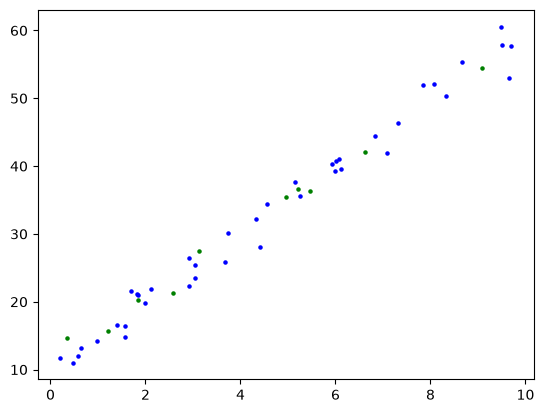

In [11]:
plt.scatter(X_train, y_train, c="b", s=5, label="Training data")
plt.scatter(X_test, y_test, c="g", s=5, label="Testing data")
plt.show()

## 3. PyTorch Yapısal Model Mimarisi (nn.Linear)

> 🧠 **Neden `nn.Linear` Kullanıyoruz?**
- Notebook 6'da `weights` ve `bias` parametrelerini elle (`nn.Parameter`) tanımlamıştık.
- `nn.Linear(in_features=1, out_features=1)` katmanı ise $Y = X \cdot W^T + b$ matris matematiğini, ağırlık ve bias parametrelerinin oluşturulmasını PyTorch arkasında otomatik halleder.
- `in_features=1`: 1 adet girdi özelliği (Ders Çalışma Saati).
- `out_features=1`: 1 adet çıktı tahmini (Sınav Notu).


In [12]:
import torch.nn as nn

# PyTorch nn.Linear katmanı kullanan yapısal doğrusal regresyon modeli
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        # nn.Linear(in_features=1, out_features=1): 1 girdi (çalışma saati) alıp 1 çıktı (not) verir
        self.linear_layer = nn.Linear(in_features=1, out_features=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)


In [13]:
torch.manual_seed(42)
model = LinearRegressionModel()


In [14]:
model

LinearRegressionModel(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)

In [15]:
model.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
             ('linear_layer.bias', tensor([0.8300]))])

## 4. Kayıp Fonksiyonu (Loss) ve İyileştirici (Optimizer)


In [16]:
# Kayıp Fonksiyonu (Loss Function): Ortalama Kare Hata (MSE)
loss_fn = nn.MSELoss()

# İyileştirici (Optimizer): SGD (Stochastic Gradient Descent), lr = 0.001
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.001)


## 5. Modelin Eğitilmesi (Training Loop - 5 Altın Adım)

> 🔄 **Eğitim Döngüsünün (Training Loop) 5 Altın Adımı:**
1. **`model.train()`**: Modeli eğitim moduna alır.
2. **`y_pred = model(X_train)` (Forward Pass):** Model mevcut ağırlıklarla tahmin üretir.
3. **`loss = loss_fn(y_pred, y_train)` (Loss Calculation):** Tahminler ile gerçek değerler arasındaki hatayı hesaplar.
4. **`optimizer.zero_grad()` (Zero Gradients):** Önceki adımdan kalan gradyan sayaçlarını sıfırlar.
5. **`loss.backward()` (Backpropagation):** Hatayı modele geriye doğru yayarak parametrelerin türevini alır.
6. **`optimizer.step()` (Gradient Descent Step):** Türev değerine ve öğrenme oranına (`lr`) göre ağırlıkları ve bias'ı günceller.


In [17]:
epochs = 120

# 120 Epoch boyunca 5 Altın Eğitim Adımı
for epoch in range(epochs):
    # 0. Modeli eğitim moduna al
    model.train()

    # 1. Forward Pass (Tahmin Et)
    y_pred = model(X_train)

    # 2. Loss Calculation (Hatayı Hesapla)
    loss = loss_fn(y_pred, y_train)

    # 3. Zero Grad (Gradyan Sayaçlarını Sıfırla)
    optimizer.zero_grad()

    # 4. Backward Pass (Geriye Yayılım / Türev Al)
    loss.backward()

    # 5. Optimizer Step (Ağırlıkları Güncelle)
    optimizer.step()

    # Test / Değerlendirme Adımı
    model.eval()
    with torch.inference_mode():
        test_pred = model(X_test)
        test_loss = loss_fn(test_pred, y_test)

        if epoch % 5 == 0:
            print(f"Epoch: {epoch:3d} | Train Loss: {loss:.4f} | Test Loss: {test_loss:.4f}")


epoch: 0, Train loss:965.6339111328125, test loss:717.6834106445312
epoch: 5, Train loss:530.086669921875, test loss:405.685546875
epoch: 10, Train loss:295.73614501953125, test loss:236.0322723388672
epoch: 15, Train loss:169.6184539794922, test loss:143.42544555664062
epoch: 20, Train loss:101.72415924072266, test loss:92.61088562011719
epoch: 25, Train loss:65.15110778808594, test loss:64.53107452392578
epoch: 30, Train loss:45.427330017089844, test loss:48.86598587036133
epoch: 35, Train loss:34.76780319213867, test loss:40.014488220214844
epoch: 40, Train loss:28.9846248626709, test loss:34.927181243896484
epoch: 45, Train loss:25.82492446899414, test loss:31.93711280822754
epoch: 50, Train loss:24.0767879486084, test loss:30.128173828125
epoch: 55, Train loss:23.088253021240234, test loss:28.993366241455078
epoch: 60, Train loss:22.508625030517578, test loss:28.2496337890625
epoch: 65, Train loss:22.149234771728516, test loss:27.73710060119629
epoch: 70, Train loss:21.90858459472

In [18]:
X_train.dtype

torch.float32

In [19]:
X_train.shape

torch.Size([40, 1])

## 6. Eğitilmiş Model İle Nihai Tahminler (Evaluation)

> 🎉 **Eğitilmiş Modelin Başarısı:**
- Başlangıçta rastgele atanan `weight` ve `bias` değerleri, 120 epoch sonunda yaklaşık **weight $\approx$ 6.2079** ve **bias $\approx$ 2.2388** değerlerine güncellenmiştir.
- Grafikte kırmızı renkte gösterilen eğitilmiş tahminler (`y_preds`), yeşil renkteki gerçek test değerlerinin (`y_test`) tam üzerine oturmuştur!


In [20]:
# Eğitilmiş modelin öğrendiği güncel ağırlık (weight) ve bias değerleri
print(model.state_dict())


OrderedDict({'linear_layer.weight': tensor([[6.2079]]), 'linear_layer.bias': tensor([2.2388])})


In [21]:
model.eval()
with torch.inference_mode():
    y_preds = model(X_test)

In [24]:
y_preds #tahminlerimiz

tensor([[ 9.8148],
        [32.9787],
        [ 4.3736],
        [58.6882],
        [18.3035],
        [43.3673],
        [21.5894],
        [34.5239],
        [36.1778],
        [13.7143]])

In [25]:
y_test

tensor([[15.6626],
        [35.4731],
        [14.6752],
        [54.4295],
        [21.3220],
        [42.1226],
        [27.4164],
        [36.6609],
        [36.2760],
        [20.2693]])

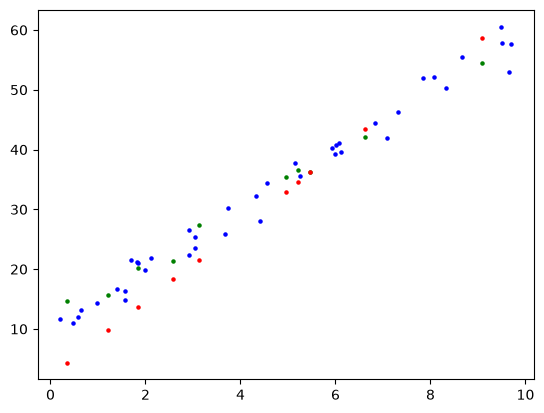

In [26]:
# Eğitilmiş model tahminlerinin görselleştirilmesi
plt.scatter(X_train, y_train, c="b", s=5, label="Eğitim Verisi (Train)")
plt.scatter(X_test, y_test, c="g", s=5, label="Gerçek Test Verisi (y_test)")
plt.scatter(X_test, y_preds, c="r", s=5, label="Eğitilmiş Tahminler (y_preds)")
plt.legend()
plt.show()


## 7. Modeli İyileştirme & Kapasite Artırma (Underfitting)

> 💡 **Eğer Model Yetersiz Kalırsa (Underfitting):**
1. Daha fazla katman veya nöron eklenebilir (`nn.Linear` katman sayısı artırılabilir).
2. Doğrusal olmayan (non-linear) aktivasyon fonksiyonları eklenebilir (`torch.relu` vb.).
3. Epoch sayısı artırılabilir veya `learning rate` (öğrenme oranı) ayarlanabilir.
4. Veri seti büyütülebilir veya yeni özellikler (features) eklenebilir.


In [27]:
# Modeli geliştirmek için kullanabileceğimiz teknikler:
# 1. Katman ve Nöron sayısını artırmak (Model Kapasitesi)
# 2. Aktivasyon fonksiyonları eklemek (ReLU vb.)
# 3. Epoch sayısını ve öğrenme oranını (learning rate) optimize etmek


---
### 📌 07. Yapısal Model Eğitimi - Özet Cheat Sheet

| Kavram | Fonksiyon / Yapı | Açıklama |
| :--- | :--- | :--- |
| **Hazır Lineer Katman** | `nn.Linear(in_features, out_features)` | $Y = X \cdot W^T + b$ matematiğini otomatik yönetir |
| **Veri Tipi Şartı** | `dtype=torch.float32` | `nn.Linear` float32 veri tipi bekler |
| **Boyut Şartı** | `.unsqueeze(1)` | `(N)` şeklindeki 1D tensörü `(N, 1)` şeklindeki 2D tensöre çevirir |
| **Parametre Listesi** | `model.state_dict()` | Katmanın güncellenen ağırlık ve bias değerlerini verir |
| **Eğitim Döngüsü** | `train -> forward -> loss -> zero_grad -> backward -> step` | Derin öğrenme eğitiminin 5 altın adımı |
